# AIA Project: Breast Cancer Diagnosis Prediction using Machine Learning

**Course:** Artificial Intelligence & Analytics (AIA)  
**Student:** Rohit Kumar Tiwari, BCA (AI & ML with IBM), United University, Prayagraj

---

## Project Overview
This project builds a machine learning classifier that predicts whether a breast tumour is **Malignant (M)** or **Benign (B)** from measurements of cell nuclei taken from digitised images of a fine needle aspirate (FNA) of a breast mass.

**Dataset:** *Breast Cancer Wisconsin (Diagnostic) Data Set* (Kaggle / UCI ML Repository)  
**Problem type:** Supervised binary classification  
**Target column:** `diagnosis` (M = malignant, B = benign)

### Workflow
1. Load the dataset
2. Model selection (which model suits this data, and why)
3. Data cleaning & preprocessing (missing values, duplicates, encoding, correlation)
4. Train / test split
5. Model training
6. Model evaluation
7. Conclusion

## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance

import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries imported successfully")

Libraries imported successfully


## 2. Load the Dataset
The dataset file is stored in the `data/` folder of this repository.

In [2]:
df = pd.read_csv("data/data.csv")

print("Shape of the dataset (rows, columns):", df.shape)
display(df.head())

Shape of the dataset (rows, columns): (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842303,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,842304,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,842305,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,842306,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [4]:
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
id,569.0,842586.000,164.400,842302.000,842444.000,842586.000,842728.000,842870.000
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave_points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304


## 3. Choosing the Best Model

**Dataset characteristics**
- Small dataset (569 rows) with 30 numeric features
- Binary target (malignant vs benign), moderately balanced (about 63% / 37%)
- Features are continuous measurements on different scales and many are strongly correlated

**Candidate models and why they fit**

| Model | Suitability for this data |
|---|---|
| Logistic Regression | Strong, interpretable baseline; works well when classes are nearly linearly separable |
| **Support Vector Machine (RBF kernel)** | Excellent on small, high-dimensional, scaled numeric data; handles correlated features and non-linear boundaries |
| Random Forest | Robust, needs no scaling, gives feature importance, but can overfit small datasets |
| Gradient Boosting | Powerful but needs tuning and gains little on a dataset this small |
| K-Nearest Neighbours | Simple, but sensitive to feature scale and noise |
| Deep Learning (neural network) | Not suitable: 569 samples is too few, risk of overfitting and little benefit over classical models |

We compare these models objectively using cross-validation on the **training data only** (Section 6). The top models score very close to each other, so we also look at stability (standard deviation across folds) and tuning potential. On that basis we select a **Support Vector Machine**, keeping Logistic Regression as a baseline.

## 4. Data Cleaning and Preprocessing

### 4.1 Handle Missing Values

In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print("Columns with missing values:")
display(missing.to_frame("missing_count").assign(percent=lambda d: (d.missing_count / len(df) * 100).round(1)))

Columns with missing values:


,missing_count,percent
Unnamed: 32,569,100.0


The column `Unnamed: 32` is completely empty (100% missing, a trailing-comma artefact in the CSV), so it carries no information and is dropped. The `id` column is only a record identifier, not a feature, so it is also dropped. If a feature column had only a few missing values, we would impute it (median for numeric features) instead of dropping it.

In [6]:
df = df.drop(columns=["Unnamed: 32", "id"])

# Safety net: impute any remaining numeric gaps with the median (none expected here)
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

print("Remaining missing values:", int(df.isnull().sum().sum()))
print("New shape:", df.shape)

Remaining missing values: 0
New shape: (569, 31)


### 4.2 Identify and Remove Duplicate Records

In [7]:
dup_count = df.duplicated().sum()
print("Duplicate rows found:", dup_count)

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows found: 0
Shape after removing duplicates: (569, 31)


### 4.3 Encode Categorical Data
The only categorical column is the target `diagnosis`. It is encoded as **M = 1 (malignant, the positive class)** and **B = 0 (benign)**.

In [8]:
print("Categorical columns:", df.select_dtypes(include="object").columns.tolist())
print()
print("Class distribution before encoding:")
display(df["diagnosis"].value_counts().to_frame("count").assign(percent=lambda d: (d["count"] / len(df) * 100).round(1)))

le = LabelEncoder().fit(["B", "M"])          # B -> 0, M -> 1
df["diagnosis"] = le.transform(df["diagnosis"])
print("Encoding:", {str(k): int(v) for k, v in zip(le.classes_, le.transform(le.classes_))})

Categorical columns: ['diagnosis']

Class distribution before encoding:
Encoding: {'B': 0, 'M': 1}


,count,percent
diagnosis,,
B,357,62.7
M,212,37.3


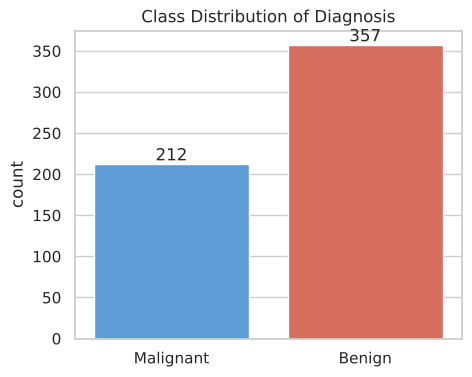

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=df["diagnosis"].map({0: "Benign", 1: "Malignant"}), palette=["#4c9be8", "#e8604c"], ax=ax)
ax.set_title("Class Distribution of Diagnosis")
ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

### 4.4 Analyse Correlation Between Features

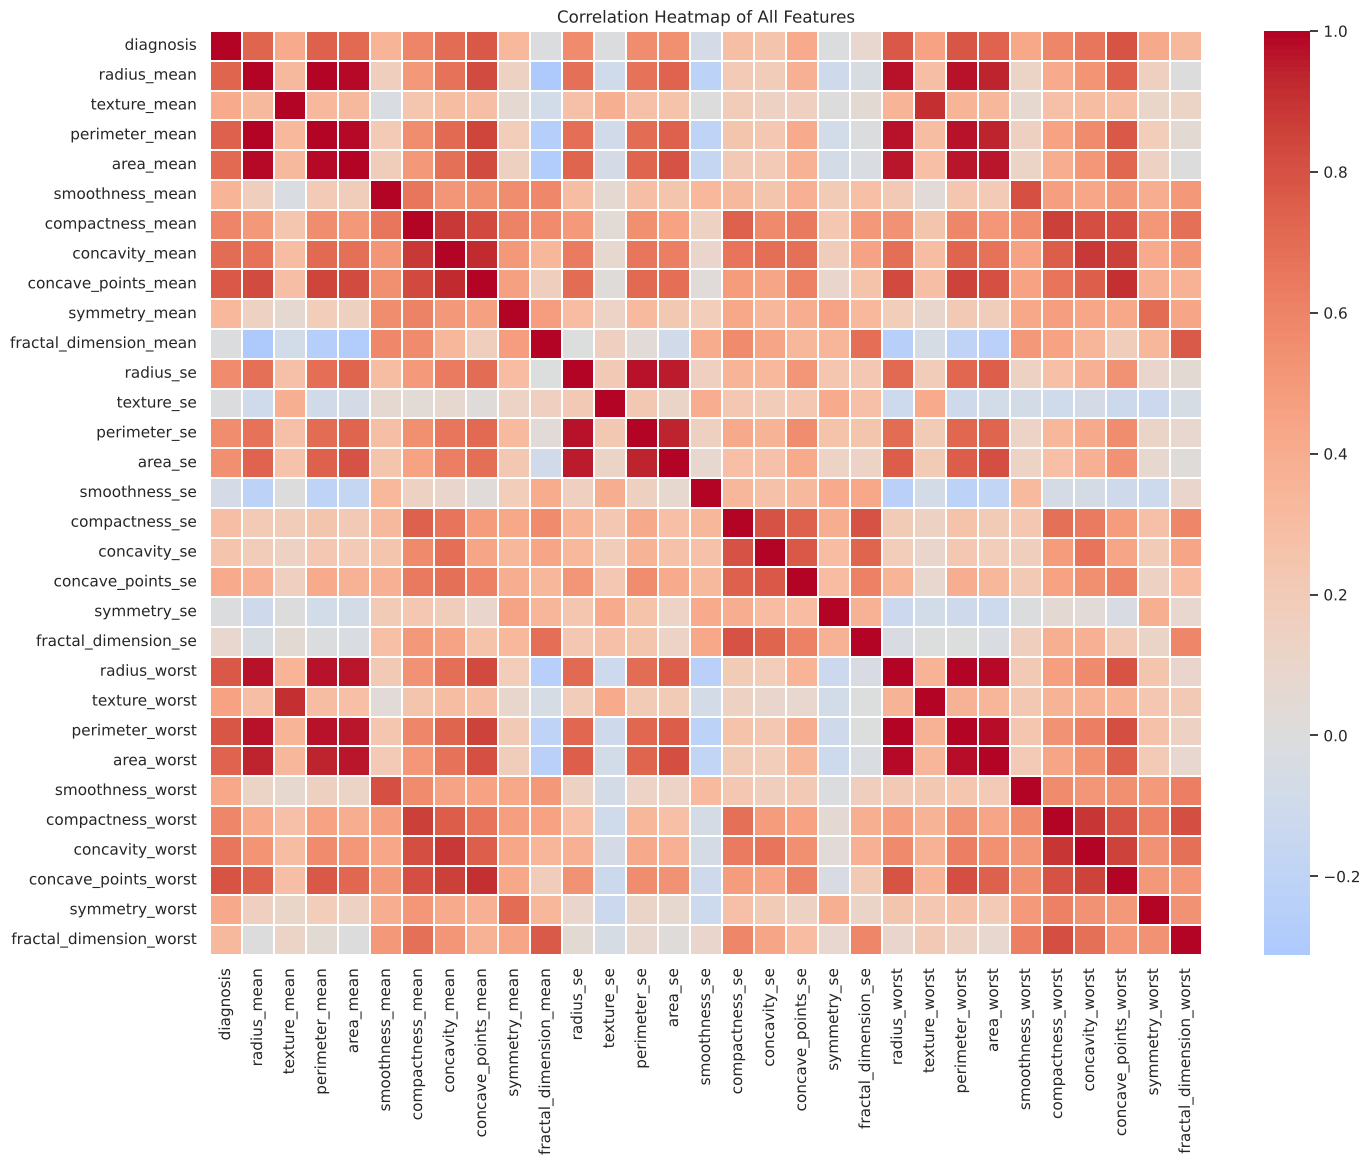

In [10]:
corr = df.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation Heatmap of All Features")
plt.show()

In [11]:
# Features most correlated with the target
target_corr = corr["diagnosis"].drop("diagnosis").sort_values(ascending=False)
print("Top 10 features positively correlated with malignancy:")
display(target_corr.head(10).round(3).to_frame("correlation"))
print("Top 5 features negatively correlated with malignancy:")
display(target_corr.tail(5).round(3).to_frame("correlation"))

Top 10 features positively correlated with malignancy:
Top 5 features negatively correlated with malignancy:


,correlation
concave_points_worst,0.794
perimeter_worst,0.783
concave_points_mean,0.777
radius_worst,0.776
perimeter_mean,0.743
area_worst,0.734
radius_mean,0.730
area_mean,0.709
concavity_mean,0.696
concavity_worst,0.660


,correlation
fractal_dimension_se,0.078
symmetry_se,-0.007
texture_se,-0.008
fractal_dimension_mean,-0.013
smoothness_se,-0.067


In [12]:
# Highly correlated feature pairs (|r| > 0.95) mean redundant information (multicollinearity)
features = df.drop(columns="diagnosis")
fcorr = features.corr().abs()
upper = fcorr.where(np.triu(np.ones(fcorr.shape), k=1).astype(bool))

pairs = (upper.stack().reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_correlation"})
         .query("abs_correlation > 0.95")
         .sort_values("abs_correlation", ascending=False))
display(pairs.round(3))

to_drop = [c for c in upper.columns if any(upper[c] > 0.95)]
print("Redundant features dropped (|r| > 0.95):", to_drop)

Redundant features dropped (|r| > 0.95): ['perimeter_mean', 'area_mean', 'perimeter_se', 'area_se', 'radius_worst', 'perimeter_worst', 'area_worst']


,feature_1,feature_2,abs_correlation
2,radius_mean,perimeter_mean,0.998
622,radius_worst,perimeter_worst,0.994
3,radius_mean,area_mean,0.987
63,perimeter_mean,area_mean,0.987
623,radius_worst,area_worst,0.984
683,perimeter_worst,area_worst,0.978
312,radius_se,perimeter_se,0.973
82,perimeter_mean,perimeter_worst,0.970
20,radius_mean,radius_worst,0.970
80,perimeter_mean,radius_worst,0.969


In [13]:
df = df.drop(columns=to_drop)
print("Shape after removing redundant features:", df.shape)

Shape after removing redundant features: (569, 24)


### 4.5 Other Preprocessing Steps
- **Outlier check:** boxplots are used to inspect outliers. In this medical dataset, extreme values are genuine measurements of large tumours, so they are kept rather than removed.
- **Feature scaling:** `StandardScaler` is applied inside a pipeline (fitted on training data only) to prevent data leakage.

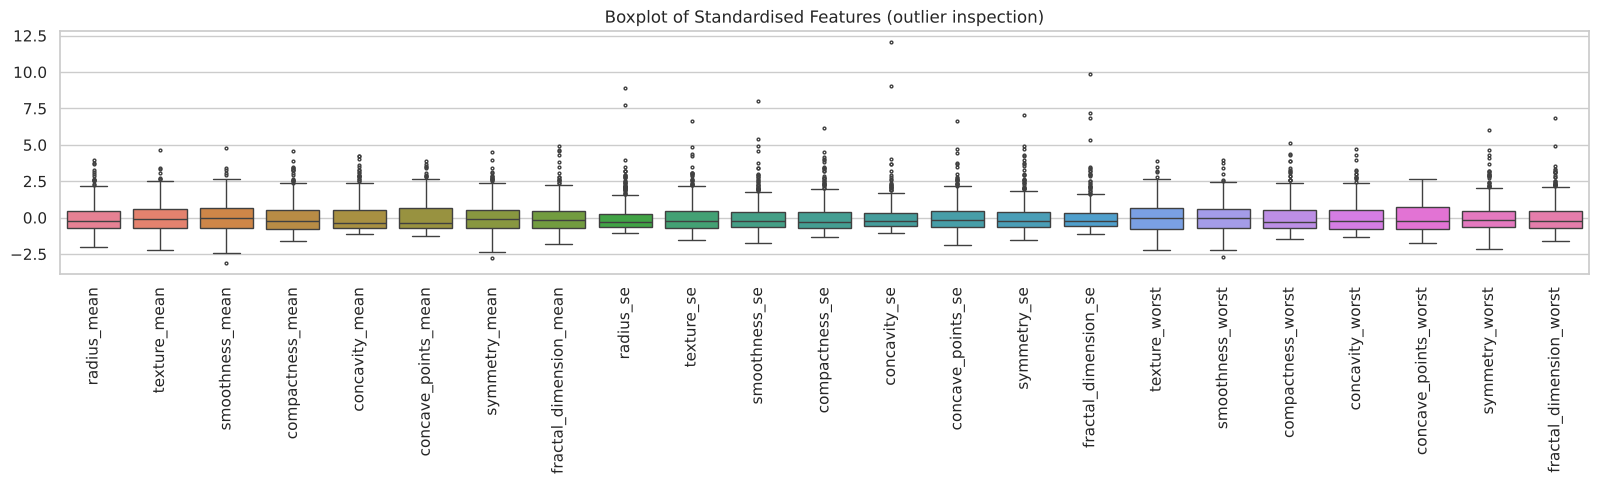

In [14]:
X_vis = df.drop(columns="diagnosis")
scaled_vis = (X_vis - X_vis.mean()) / X_vis.std()

plt.figure(figsize=(16, 5))
sns.boxplot(data=scaled_vis, orient="v", fliersize=2)
plt.xticks(rotation=90)
plt.title("Boxplot of Standardised Features (outlier inspection)")
plt.tight_layout()
plt.show()

## 5. Data Splitting
The data is split **80% training / 20% testing**. A *stratified* split keeps the proportion of malignant and benign cases the same in both sets.

In [15]:
X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape, "| Testing set:", X_test.shape)
print("Malignant share in train: {:.1%} | in test: {:.1%}".format(y_train.mean(), y_test.mean()))

Training set: (455, 23) | Testing set: (114, 23)
Malignant share in train: 37.4% | in test: 36.8%


## 6. Model Training and Selection (Cross-Validation on Training Data)
Each candidate model is evaluated with 5-fold stratified cross-validation on the **training set only**, so the test set remains untouched for the final evaluation.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "SVM (RBF)":           Pipeline([("scaler", StandardScaler()), ("clf", SVC(probability=True, random_state=RANDOM_STATE))]),
    "K-Nearest Neighbours":Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
    "Random Forest":       Pipeline([("clf", RandomForestClassifier(random_state=RANDOM_STATE))]),
    "Gradient Boosting":   Pipeline([("clf", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
}

rows = []
for name, model in candidates.items():
    acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    f1  = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
    rows.append({"Model": name, "CV Accuracy": acc.mean(), "CV Std": acc.std(), "CV F1": f1.mean()})

cv_results = pd.DataFrame(rows).sort_values("CV Accuracy", ascending=False).reset_index(drop=True)
display(cv_results.round(4))

,Model,CV Accuracy,CV Std,CV F1
0,Logistic Regression,0.9692,0.0189,0.9574
1,Gradient Boosting,0.9670,0.0120,0.9554
2,SVM (RBF),0.9670,0.0070,0.9554
3,K-Nearest Neighbours,0.9604,0.0149,0.9451
4,Random Forest,0.9538,0.0273,0.9368


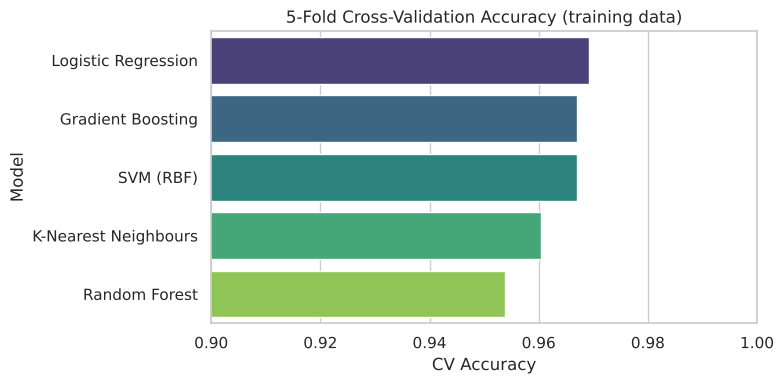

In [17]:
plt.figure(figsize=(8, 4))
sns.barplot(data=cv_results, y="Model", x="CV Accuracy", palette="viridis")
plt.xlim(0.9, 1.0)
plt.title("5-Fold Cross-Validation Accuracy (training data)")
plt.tight_layout()
plt.show()

### Hyperparameter Tuning of the Selected Model (SVM)
`GridSearchCV` searches for the best `C`, `gamma` and kernel for the SVM, using cross-validation on the training set.

In [18]:
svm_pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC(probability=True, random_state=RANDOM_STATE))])

param_grid = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__gamma": ["scale", 0.1, 0.01, 0.001],
    "clf__kernel": ["rbf", "linear"],
}

grid = GridSearchCV(svm_pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy: {:.4f}".format(grid.best_score_))

best_model = grid.best_estimator_

Best parameters: {'clf__C': 100, 'clf__gamma': 0.001, 'clf__kernel': 'rbf'}
Best CV accuracy: 0.9780


## 7. Model Evaluation
The tuned model is now evaluated on the **unseen test set**.

In [19]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_prob),
}
display(pd.Series(metrics, name="Test score").round(4).to_frame())

,Test score
Accuracy,0.9737
Precision,1.0000
Recall,0.9286
F1-score,0.9630
ROC-AUC,0.9954


In [20]:
print(classification_report(y_test, y_pred, target_names=["Benign (0)", "Malignant (1)"]))

               precision    recall  f1-score   support

   Benign (0)       0.96      1.00      0.98        72
Malignant (1)       1.00      0.93      0.96        42

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114



True Negatives: 72 | False Positives: 0 | False Negatives: 3 | True Positives: 39


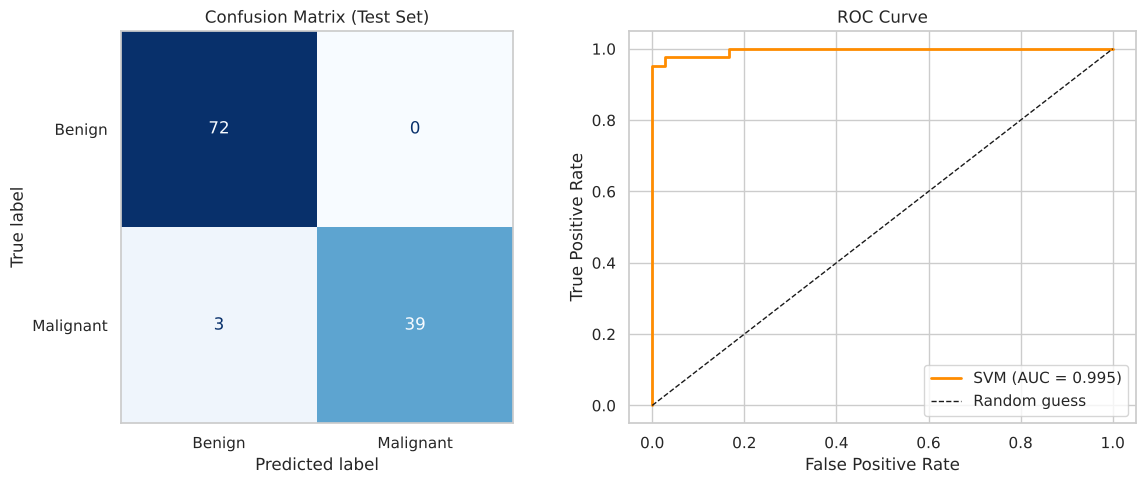

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix (Test Set)")
axes[0].grid(False)

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label="SVM (AUC = {:.3f})".format(metrics["ROC-AUC"]))
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn} | False Positives: {fp} | False Negatives: {fn} | True Positives: {tp}")

In [22]:
# Baseline comparison: tuned SVM vs plain Logistic Regression on the same test set
baseline = candidates["Logistic Regression"].fit(X_train, y_train)
b_pred = baseline.predict(X_test)

comparison = pd.DataFrame({
    "Tuned SVM": [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred), f1_score(y_test, y_pred)],
    "Logistic Regression": [accuracy_score(y_test, b_pred), precision_score(y_test, b_pred), recall_score(y_test, b_pred), f1_score(y_test, b_pred)],
}, index=["Accuracy", "Precision", "Recall", "F1-score"])
display(comparison.round(4))

,Tuned SVM,Logistic Regression
Accuracy,0.9737,0.9649
Precision,1.0000,0.9750
Recall,0.9286,0.9286
F1-score,0.9630,0.9512


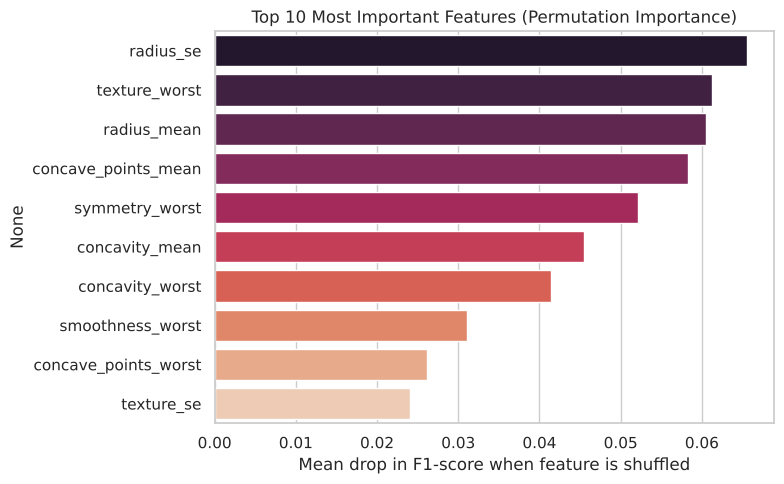

In [23]:
# Which features matter most? (permutation importance on the test set)
perm = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring="f1")
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, palette="rocket")
plt.title("Top 10 Most Important Features (Permutation Importance)")
plt.xlabel("Mean drop in F1-score when feature is shuffled")
plt.tight_layout()
plt.show()

## 8. Save the Trained Model

In [24]:
joblib.dump(best_model, "svm_breast_cancer_model.joblib")
print("Model saved as svm_breast_cancer_model.joblib")

Model saved as svm_breast_cancer_model.joblib


## 9. Conclusion

- The **Breast Cancer Wisconsin (Diagnostic)** dataset was cleaned: the fully empty `Unnamed: 32` column and the `id` column were removed, no duplicate records were found, the `diagnosis` target was label-encoded (M = 1, B = 0), and highly correlated, redundant features (|r| > 0.95) were removed.
- Five models were compared with 5-fold cross-validation on the training set. Logistic Regression, Gradient Boosting and the **SVM (RBF kernel)** scored within about 0.2% of each other (roughly 96.7% to 96.9% accuracy), ahead of KNN and Random Forest. The SVM was selected because it had the most stable results across folds (lowest standard deviation) and the most room for improvement through tuning, which suits small, scaled, nearly separable numeric data.
- After hyperparameter tuning with GridSearchCV (best: RBF kernel, C = 100, gamma = 0.001), the SVM reached about **97.4% accuracy, 100% precision, 92.9% recall and a ROC-AUC of 0.995** on the unseen test set, slightly better than the Logistic Regression baseline (96.5% accuracy). On this small test set (114 samples) the difference between the two models is only a few cases, so it should not be over-interpreted.
- In a medical setting **recall for the malignant class** matters most, because a missed cancer (false negative) is far more costly than a false alarm. In our run the model missed 3 of 42 malignant cases (false negatives) and raised no false alarms, so improving recall (for example by adjusting the decision threshold) is the main area to improve.
- **Limitations:** the dataset is small (569 samples) and comes from a single source, so results should be validated on external data. This model is an educational project and **not a clinical diagnostic tool**.
- **Future work:** try ensemble stacking, test on additional datasets, and build a simple web app for predictions.